In [81]:
import numpy as np
import matplotlib.pyplot as plt
from starter_pack.code.utils import *
from starter_pack.code.align_images import *
# kernal
K = np.array([1, 4, 6, 4, 1], dtype=np.float64) / 16.0

In [63]:
def blur_axis(im, k, axis):
    """1D convolution using reflect padding, same output size."""
    r = len(k) // 2
    pad = [(0, 0)] * im.ndim
    pad[axis] = (r, r)
    p = np.pad(im, pad, mode="reflect")
    n = im.shape[axis]
    out = np.zeros(im.shape, dtype=np.float64)
    for i, w in enumerate(k):                    # loop over taps, not pixels
        out += w * np.take(p, np.arange(i, i + n), axis=axis)
    return out

In [64]:
def blur(im):
    """Blur with k along x and y."""
    return blur_axis(blur_axis(im, K, 0), K, 1)

In [65]:
def reduce(im):
    """Blur, then reduce by a factor of 2."""
    if im.ndim == 3:
        return np.stack([reduce(im[..., c]) for c in range(im.shape[2])], axis=-1)
   
    return blur(im)[::2, ::2]

In [66]:
def expand(im, shape=None):
    """Upsample by 2 . If `shape` is given,
    crop the result to it."""
    if im.ndim == 3:
        return np.stack([expand(im[..., c], shape) for c in range(im.shape[2])], axis=-1)
   
    H, W = im.shape[:2]
    up = np.zeros((2 * H, 2 * W) + im.shape[2:], dtype=np.float64)
    up[::2, ::2] = im
    out = 4.0 * blur(up)
    if shape is not None:
        out = out[:shape[0], :shape[1]]
    return out

In [67]:
def gaussian_pyramid(im, levels):
    gp = [im.astype(np.float64)]
    for _ in range(levels - 1):
        gp.append(reduce(gp[-1]))
    return gp

In [68]:
def laplacian_pyramid(im, levels):
    gp = gaussian_pyramid(im, levels)
    lp = [gp[i] - expand(gp[i + 1], gp[i].shape) for i in range(len(gp) - 1)]
    lp.append(gp[-1])                            # smallest Gaussian level itself
    return lp

In [69]:
def reconstruct(lp):
    cur = lp[-1]
    for L in reversed(lp[:-1]):
        cur = expand(cur, L.shape) + L
    return cur

In [70]:
def pyramid_canvas(levels, boost=None):
    """ Laplacian display"""
    H = levels[0].shape[0]
    W = sum(l.shape[1] for l in levels) + 10 * (len(levels) - 1)
    shape = (H, W) + levels[0].shape[2:]
    canvas = np.ones(shape, dtype=np.float64)
    x = 0
    for i, l in enumerate(levels):
        last = i == len(levels) - 1  
        if last:
            # The smallest Gaussian level is a normal image
            d = l
        else:
            # Display detail coefficients around middle gray
            scale = boost if boost is not None else 3.0
            d = 0.5 + scale * l                  # smallest Gaussian level: show as is
        # d = l if (boost is None or last) else 0.5 + boost * l   # zero -> mid-gray
        canvas[:l.shape[0], x:x + l.shape[1]] = np.clip(d, 0, 1)
        x += l.shape[1] + 10
    return canvas

image shape: (418, 600, 3)
level shapes: [(418, 600), (209, 300), (105, 150), (53, 75), (27, 38)]
max abs error: 0.0
pyramid size / image size: 1.3327392344497608


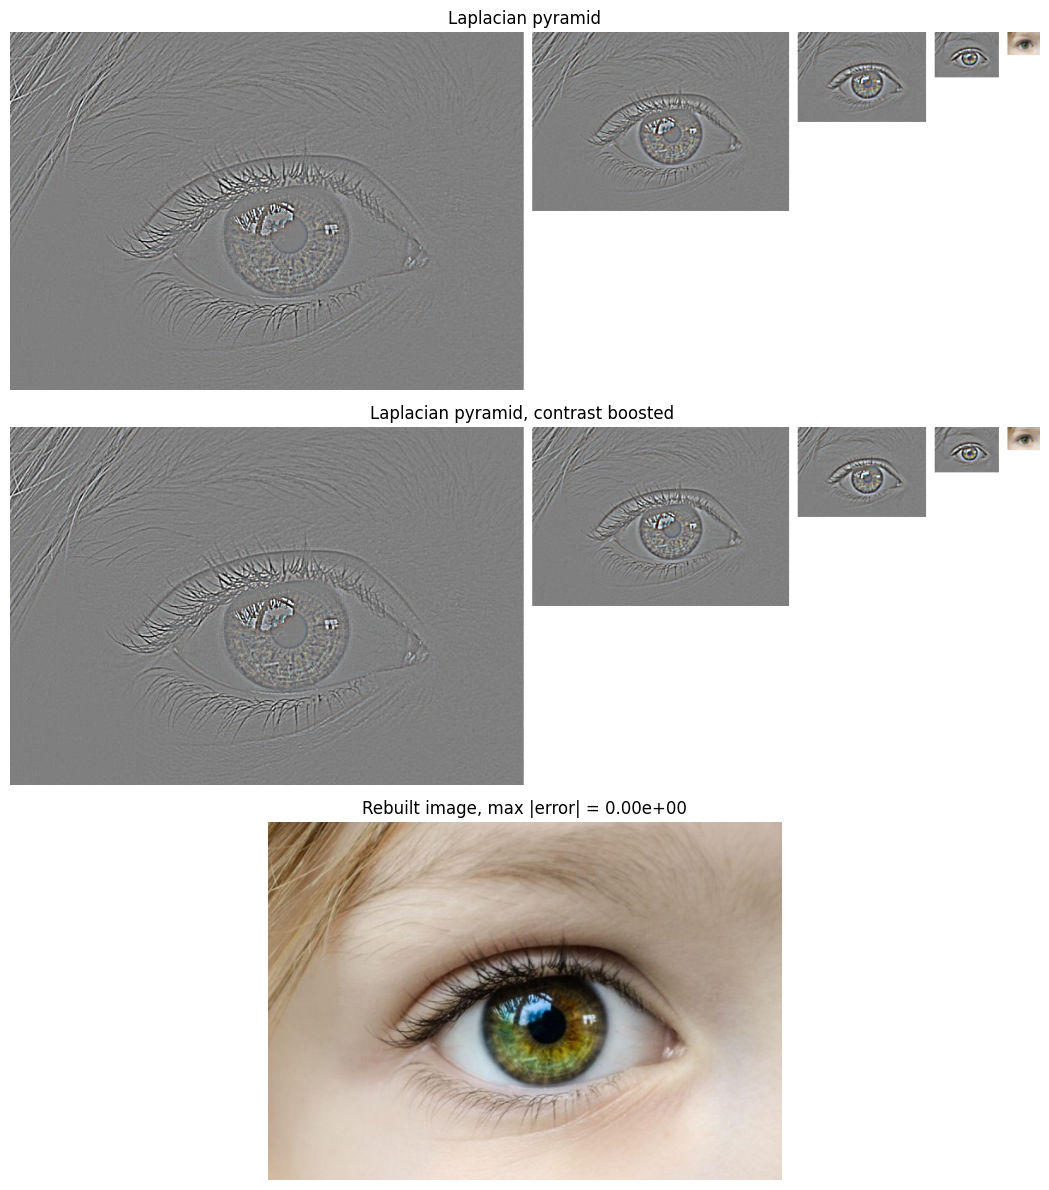

In [ ]:
path = "starter_pack/images/part2_frequencies/eye.jpg"
im = load_image(path)                        
levels = 5
# gp = gaussian_pyramid(im, levels)
lp = laplacian_pyramid(im, levels)
rec = reconstruct(lp)
err = np.abs(rec - im)
print("image shape:", im.shape)
print("level shapes:", [g.shape[:2] for g in lp])
print("max abs error:", err.max())
total = sum(g.shape[0] * g.shape[1] for g in lp)
print("pyramid size / image size:", total / (im.shape[0] * im.shape[1]))
 
fig, ax = plt.subplots(3, 1, figsize=(12, 12))
cm = "gray" if im.ndim == 2 else None
ax[0].imshow(pyramid_canvas(lp), cmap=cm); ax[0].set_title("Laplacian pyramid")
ax[1].imshow(pyramid_canvas(lp, boost=3.0), cmap=cm)
ax[1].set_title("Laplacian pyramid, contrast boosted ")
ax[2].imshow(np.clip(rec, 0, 1), cmap=cm)
ax[2].set_title(f"Rebuilt image, max |error| = {err.max():.2e}")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("pyramids.png", dpi=150); plt.show()

# part2.4

In [72]:
def blend(im1, im2, mask, levels):
    """im1, im2: (H,W,3) in [0,1]; mask: (H,W) float 0/1 (1 -> im1)."""
    L1 = laplacian_pyramid(im1, levels)
    L2 = laplacian_pyramid(im2, levels)
    GM = gaussian_pyramid(mask, levels)

    LS, parts = [], []
    for l1, l2, m in zip(L1, L2, GM):
        m = m[..., None] if l1.ndim == 3 else m
        a = m * l1            # M * L1
        b = (1 - m) * l2      # (1-M) * L2
        LS.append(a + b)
        parts.append((a, b))
    return np.clip(reconstruct(LS), 0, 1), parts

In [73]:
def hard_cut(im1, im2, mask):
    m = mask[..., None] if im1.ndim == 3 else mask
    return m * im1 + (1 - m) * im2

In [74]:
def show_levels(parts):
    n = len(parts)
    fig, ax = plt.subplots(n, 3, figsize=(9, 3 * n))
    for i, (a, b) in enumerate(parts):
        off = 0.5 if i < n - 1 else 0.0     # mid-gray for band-pass levels
        for j, im in enumerate([a, b, a + b]):
            ax[i, j].imshow(np.clip(im + off, 0, 1)); ax[i, j].axis("off")
    ax[0, 0].set_title("M·L1"); ax[0, 1].set_title("(1−M)·L2"); ax[0, 2].set_title("sum")
    plt.tight_layout()
    plt.show()

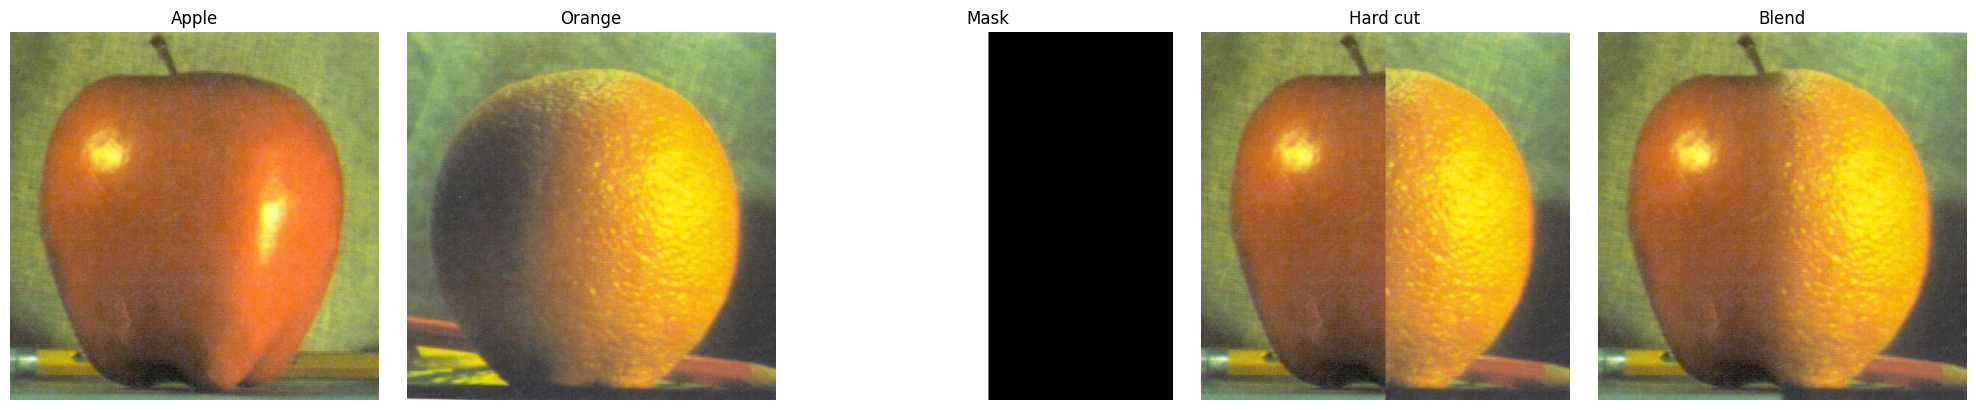

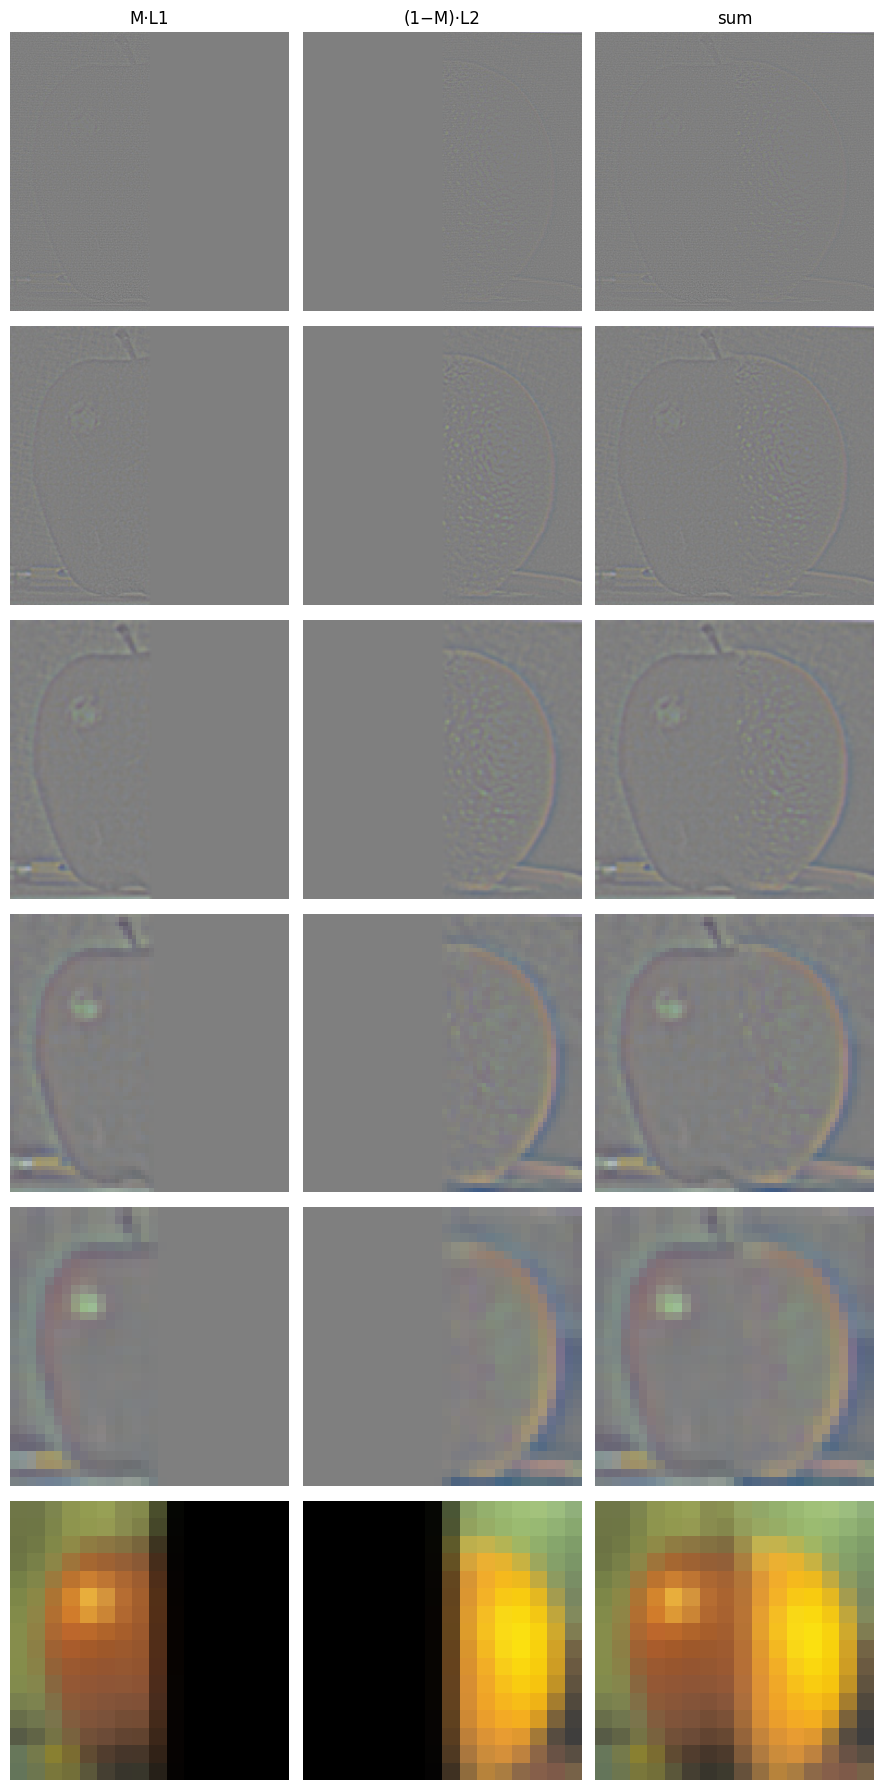

In [75]:
apple  = load_image("starter_pack/images/part2_frequencies/apple.jpg")
orange = load_image("starter_pack/images/part2_frequencies/orange.jpg")
H, W = apple.shape[:2]

mask = np.zeros((H, W), np.float32)
mask[:, :W // 2] = 1                       # left half white

result, parts = blend(apple, orange, mask, levels=6)
show(apple, orange, mask, hard_cut(apple, orange, mask), result,
     titles=["Apple", "Orange", "Mask", "Hard cut", "Blend"])
show_levels(parts) 

In [86]:
def fit_size(im, max_side=1000):
    """Bring an image to <= max_side on its longer side. Pick align points AFTER this."""
    s = max_side / max(im.shape[:2])
    if s >= 1:
        return im
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

In [87]:
def match_height(im, target_h):
    s = target_h / im.shape[0]
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)



In [102]:
import cv2, numpy as np
from starter_pack.code.utils import load_image, show

A = load_image("images.jpg")                     # dark red, textured (portrait)
B = load_image("images.png")                     # flat bright red (landscape)
B = cv2.resize(B, (A.shape[1], A.shape[0]))      # cv2.resize takes (width, height)

H, W = A.shape[:2]


m8 = np.zeros((H, W), np.uint8)
cv2.ellipse(m8, (W // 2, H // 2), (W // 3, H // 4), 0, 0, 360, 1, -1)
mask = m8.astype(np.float32)                     

result, parts = blend(A, B, mask, levels=5)
show(A, B, mask, hard_cut(A, B, mask), result,
     titles=["A", "B", "Mask", "Hard cut", "Blend"])
show_levels(parts)

In [101]:
import cv2, numpy as np
from starter_pack.code.utils import load_image, show

A = load_image("moon.jpg")                    
B = load_image("sky.jpg")                     
B = cv2.resize(B, (A.shape[1], A.shape[0]))      

H, W = A.shape[:2]

# irregular mask: an ellipse in the middle (white -> A, black -> B)
m8 = np.zeros((H, W), np.uint8)
cv2.ellipse(m8, (W // 2, H // 2), (W // 3, H // 4), 0, 0, 360, 1, -1)
mask = m8.astype(np.float32)                    

result, parts = blend(A, B, mask, levels=5)
show(A, B, mask, hard_cut(A, B, mask), result,
     titles=["A", "B", "Mask", "Hard cut", "Blend"])
show_levels(parts)

In [84]:
%matplotlib qt